# 1 · Ingest: load the data and build the index

| **1. Ingest** (this notebook) | [2. Training](2_training.ipynb) | [3. Inference](3_inference.ipynb) |
| --- | --- | --- |
| Load the tables and build the index | Learn from past outcomes and save the model | Score every customer and build the call list |

**The business question** for all three notebooks: *which customers will place an order in the next 30 days?* The answer is a ranked call list the account team can work from.

**This notebook in one sentence:** load the customer, product and order tables, tell Kumo how they connect, and build the index the model will search for each customer's history.

| | |
| --- | --- |
| **Goes in** | Three files in `data/`: 500 customers, 10 products and 1,063 orders (synthetic sample data) |
| **Comes out** | The index, which Kumo calls a *graph snapshot*, in `scratch/kumo_work/`. Notebooks 2 and 3 reuse it |
| **In RAG terms** | Loading documents into a vector database, then checking that everything made it in |
| **Run time** | A few seconds on a laptop |

In [1]:
import pandas as pd
import shop_demo as shop   # shared setup for notebooks 1-3; the details live in shop_demo.py

shop.start()

## Step 1 · The raw data

Plain exports, one file per table, like you'd get from a CRM or an order system.
This cell only reads the files for a look (with pandas); Kumo reads them itself in step 3.

In [2]:
tables = {name: pd.read_csv(shop.DATA_DIR / f"{name}.csv") for name in ["customers", "products", "orders"]}
for name, table in tables.items():
    print(f"{name}: {len(table):,} rows")
tables["orders"].tail(3)

customers: 500 rows
products: 10 rows
orders: 1,063 rows


,order_id,customer_id,product_id,order_date,amount
1060,1061,C074,P2,2026-11-14,230
1061,1062,C080,P10,2026-11-14,620
1062,1063,C219,P1,2026-11-15,1270


## Step 2 · Tell Kumo how the tables connect

Each order belongs to one customer and is for one product.
Declaring those two links, which column is each table's ID and which column dates the orders is all the setup Kumo needs.
Nobody hand-builds summary columns such as "orders in the last 90 days"; the model learns what matters from the records themselves.

Kumo draws the picture from the definition: `PK` is a table's ID column, `FK` links to another table, `TS` is the date orders are timed by.

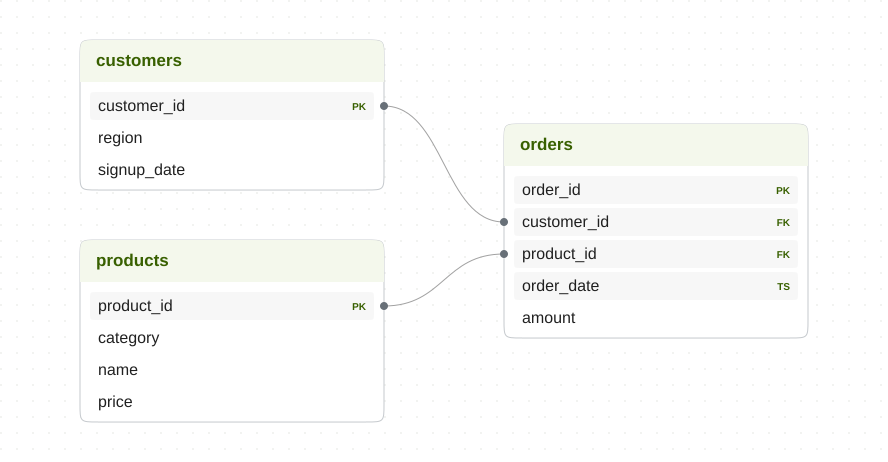

In [3]:
graph = shop.build_graph()
graph.validate()
graph.visualize(show_cols=True)

## Step 3 · Build the index

`graph.snapshot()` reads every row and writes Kumo's on-disk index, DiskGraph.
From here on, nothing reads the files again: for each customer and date, Kumo looks up that customer's recent orders and what they bought in this index.
At company scale the index sits on fast NVMe storage and feeds an NVIDIA GPU; here it is a small folder on the laptop.
The counts below are Kumo's own, from the statistics it writes next to the index.

In [4]:
snapshot = graph.snapshot()
shop.index_report(snapshot)

,Count
In the index,
customers records,500
products records,10
orders records,"1,063"
links orders → customers,"1,062"
links orders → products,"1,063"
total records / links (each link is stored both ways),"1,573 / 4,250"


## Step 4 · Health check

What made it into the index is what the model learns from, so check it in business terms.

In [5]:
shop.health_check(snapshot)

,Result,What it means
Check,,
Orders linked to a known customer,"1,062 of 1,063",1 order names a customer that isn't in the customer table
Orders linked to a known product,"1,063 of 1,063",every order's product is known
Customers with at least one order,286 of 500,the other 214 have no history; the model knows only their region and signup date


The one unlinked order, found in the file with pandas:

In [ ]:
orders, customers = tables["orders"], tables["customers"]
orders[~orders.customer_id.isin(customers.customer_id)]

Customer `C999` doesn't exist, so this order stays in the index but is never retrieved for any customer, like a document chunk whose source is missing.
One bad row in 1,063 is harmless. Kumo warns while building the index only when fewer than half of a link's rows match.

## Next

[Notebook 2](2_training.ipynb) reuses this index to turn history into practice questions and train the model.
When the data changes, run this notebook again first: Kumo builds a new index only when the data or the table definitions change, and otherwise reopens the existing one in a fraction of a second.